# RNN — DBO na entrada com 10 leituras de DQO e SST

A DBO na entrada (`DBO-E`) continua sendo o alvo. Cada exemplo guarda 10 leituras de DQO (`DQO-E`) e 10 de SST (`SS-E`): o dia estimado e as nove leituras anteriores disponíveis. A rede recorrente lê essa sequência e devolve a DBO do dia mais recente.

Dias sem uma das três medidas saem da série. Não há interpolação. A ordem da data importa aqui, porque as 10 leituras são uma fila.


In [1]:
from pathlib import Path
import sys
import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({
    "figure.figsize": (6.2, 4.6),
    "axes.grid": True,
    "grid.color": "0.85",
    "grid.linewidth": 0.6,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "medium",
})

COR = "#1f4e79"
COR_REF = "#c45c26"
SEMENTE = 42
JANELA = 10
ENTRADAS = ["DQO-E", "SS-E"]
ALVO = "DBO-E"
np.random.seed(SEMENTE)


def raiz_repositorio() -> Path:
    aqui = Path.cwd().resolve()
    for candidato in [aqui, *aqui.parents]:
        if (candidato / "data" / "water-treatment-plant" / "water-treatment.data").exists():
            return candidato
    raise FileNotFoundError("Repositório SoftSensor não encontrado.")


RAIZ = raiz_repositorio()
sys.path.insert(0, str(RAIZ / "modelo"))
from dados import carregar

FIGURAS = RAIZ / "docs" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)


## Série da entrada

As 10 leituras são os dias completos vizinhos na série ordenada. Um intervalo no calendário continua sendo um intervalo: o dia seguinte da fila é a próxima leitura disponível, não um valor interpolado.


In [2]:
bruto = carregar()
tabela = (
    bruto.dropna(subset=[ALVO, *ENTRADAS])
    .loc[:, ["data", ALVO, *ENTRADAS]]
    .sort_values("data")
    .reset_index(drop=True)
)
intervalo = tabela["data"].diff().dt.days

print(f"dias no arquivo: {len(bruto)}")
print(f"dias com DBO, DQO e SST na entrada: {len(tabela)}")
print(f"intervalo mediano entre leituras, em dias: {intervalo.median():.0f}")
print(f"leituras separadas por mais de um dia: {int((intervalo > 1).sum())}")
print(f"maior intervalo, em dias: {intervalo.max():.0f}")
tabela[[ALVO, *ENTRADAS]].describe().round(2)


dias no arquivo: 527
dias com DBO, DQO e SST na entrada: 498
intervalo mediano entre leituras, em dias: 1
leituras separadas por mais de um dia: 116
maior intervalo, em dias: 32


,DBO-E,DQO-E,SS-E
count,498.00,498.00,498.00
mean,188.72,405.36,228.74
std,62.28,119.99,139.12
min,31.00,81.00,98.00
25%,146.25,324.25,170.00
50%,182.50,397.50,198.00
75%,223.00,472.75,243.50
max,438.00,941.00,2008.00


## Janela, treino e validação cruzada

Oitenta por cento dos dias, os mais antigos, formam o treino. Os 20% mais recentes ficam para o teste. A fila não é embaralhada: janelas vizinhas compartilham nove leituras, e misturá-las colocaria o futuro dos dois lados.

A validação cruzada, só no treino, é temporal (`TimeSeriesSplit`, 5 partições). Dentro de cada partição o `StandardScaler` da DQO, do SST e da DBO usa apenas os dias de treino daquela partição. O critério é o MAE na unidade original da DBO.


In [3]:
def montar_janelas(serie, tamanho, inicio, fim):
    """Janelas de `tamanho` leituras cujo último dia cai em [inicio, fim)."""
    dqo = serie["DQO-E"].to_numpy(dtype=float)
    sst = serie["SS-E"].to_numpy(dtype=float)
    dbo = serie[ALVO].to_numpy(dtype=float)
    datas = serie["data"].to_numpy()
    xs, ys, fins, vaos = [], [], [], []
    for t in range(max(inicio, tamanho - 1), fim):
        a = t - tamanho + 1
        xs.append(np.column_stack([dqo[a:t + 1], sst[a:t + 1]]))
        ys.append(dbo[t])
        fins.append(datas[t])
        vaos.append((datas[t] - datas[a]) / np.timedelta64(1, "D"))
    return (
        np.stack(xs),
        np.asarray(ys, dtype=float),
        np.asarray(fins),
        np.asarray(vaos, dtype=float),
    )


corte = int(len(tabela) * 0.8)
X_treino, y_treino, data_treino, vao_treino = montar_janelas(tabela, JANELA, 0, corte)
X_teste, y_teste, data_teste, vao_teste = montar_janelas(tabela, JANELA, corte, len(tabela))

print(f"dias de treino: {corte}")
print(f"dias de teste: {len(tabela) - corte}")
print(f"janelas de treino: {len(X_treino)}")
print(f"janelas de teste: {len(X_teste)}")
print(f"vão mediano das 10 leituras, em dias: {np.median(np.concatenate([vao_treino, vao_teste])):.0f}")
print(f"vão máximo das 10 leituras, em dias: {np.max(np.concatenate([vao_treino, vao_teste])):.0f}")
print(f"formato de uma janela: {X_treino.shape[1:]}")


dias de treino: 398
dias de teste: 100
janelas de treino: 389
janelas de teste: 100
vão mediano das 10 leituras, em dias: 11
vão máximo das 10 leituras, em dias: 43
formato de uma janela: (10, 2)


## RNN

A rede de Elman tem uma camada recorrente com tangente hiperbólica e uma saída linear. Ela lê as 10 leituras em ordem e usa só o estado final para prever a DBO. O treino é Adam com retropropagação no tempo. A grade escolhe o tamanho do estado e a taxa de aprendizado, e para quando o MAE da partição de validação deixa de cair.


In [4]:
def iniciar(oculto, semente):
    rng = np.random.default_rng(semente)
    base = rng.normal(size=(oculto, oculto))
    q, r = np.linalg.qr(base)
    return {
        "W_xh": rng.normal(0, np.sqrt(1 / 2), size=(oculto, 2)),
        "W_hh": q * np.sign(np.diag(r)),
        "b_h": np.zeros(oculto),
        "W_hy": rng.normal(0, np.sqrt(1 / oculto), size=(oculto,)),
        "b_y": np.zeros(()),
    }


def adiante(X, params):
    n, passos, _ = X.shape
    oculto = params["b_h"].shape[0]
    estados = []
    h = np.zeros((n, oculto))
    for t in range(passos):
        z = X[:, t] @ params["W_xh"].T + h @ params["W_hh"].T + params["b_h"]
        h = np.tanh(z)
        estados.append(h)
    return estados[-1] @ params["W_hy"] + params["b_y"], estados


def retropropagar(X, estados, y, alvo, params):
    n, passos, _ = X.shape
    oculto = params["b_h"].shape[0]
    dy = 2 * (y - alvo) / n
    grads = {
        "W_hy": estados[-1].T @ dy,
        "b_y": np.array(dy.sum()),
        "W_xh": np.zeros_like(params["W_xh"]),
        "W_hh": np.zeros_like(params["W_hh"]),
        "b_h": np.zeros_like(params["b_h"]),
    }
    dh = dy[:, None] * params["W_hy"]
    for t in reversed(range(passos)):
        h = estados[t]
        anterior = estados[t - 1] if t else np.zeros((n, oculto))
        dz = dh * (1 - h ** 2)
        grads["W_xh"] += dz.T @ X[:, t]
        grads["W_hh"] += dz.T @ anterior
        grads["b_h"] += dz.sum(axis=0)
        dh = dz @ params["W_hh"]
    norma = np.sqrt(sum(np.sum(g * g) for g in grads.values()))
    if norma > 1:
        for nome in grads:
            grads[nome] *= 1 / norma
    return grads


def passo_adam(params, grads, momento, velocidade, t, taxa):
    t += 1
    for nome in params:
        momento[nome] = 0.9 * momento[nome] + 0.1 * grads[nome]
        velocidade[nome] = 0.999 * velocidade[nome] + 0.001 * grads[nome] ** 2
        m = momento[nome] / (1 - 0.9 ** t)
        v = velocidade[nome] / (1 - 0.999 ** t)
        params[nome] = params[nome] - taxa * m / (np.sqrt(v) + 1e-8)
    return t


def ajustar(X_tr, y_tr, X_va, y_va, oculto, taxa, semente, epocas=120, paciencia=12):
    sx = StandardScaler().fit(X_tr.reshape(-1, 2))
    sy = StandardScaler().fit(y_tr.reshape(-1, 1))
    Xtr = sx.transform(X_tr.reshape(-1, 2)).reshape(X_tr.shape)
    ytr = sy.transform(y_tr.reshape(-1, 1)).ravel()
    Xva = sx.transform(X_va.reshape(-1, 2)).reshape(X_va.shape)
    params = iniciar(oculto, semente)
    momento = {nome: np.zeros_like(valor) for nome, valor in params.items()}
    velocidade = {nome: np.zeros_like(valor) for nome, valor in params.items()}
    rng = np.random.default_rng(semente)
    melhor = copy.deepcopy(params)
    melhor_mae = np.inf
    melhor_epoca = 0
    espera = 0
    t = 0
    for epoca in range(1, epocas + 1):
        ordem = rng.permutation(len(Xtr))
        for inicio in range(0, len(Xtr), 64):
            idx = ordem[inicio:inicio + 64]
            y_lote, estados = adiante(Xtr[idx], params)
            grads = retropropagar(Xtr[idx], estados, y_lote, ytr[idx], params)
            t = passo_adam(params, grads, momento, velocidade, t, taxa)
        y_val, _ = adiante(Xva, params)
        previsto = sy.inverse_transform(y_val.reshape(-1, 1)).ravel()
        mae = mean_absolute_error(y_va, previsto)
        if mae < melhor_mae - 1e-4:
            melhor_mae = mae
            melhor_epoca = epoca
            melhor = copy.deepcopy(params)
            espera = 0
        else:
            espera += 1
            if espera >= paciencia:
                break
    return melhor, sx, sy, float(melhor_mae), int(melhor_epoca)


def prever(params, sx, sy, X):
    Xn = sx.transform(X.reshape(-1, 2)).reshape(X.shape)
    y, _ = adiante(Xn, params)
    return sy.inverse_transform(y.reshape(-1, 1)).ravel()


grade = []
partes = TimeSeriesSplit(n_splits=5)
for oculto in (8, 16, 32):
    for taxa in (1e-3, 1e-2):
        maes, epocas = [], []
        for i, (tr, va) in enumerate(partes.split(X_treino), start=1):
            _, _, _, mae, epoca = ajustar(
                X_treino[tr], y_treino[tr], X_treino[va], y_treino[va],
                oculto, taxa, SEMENTE + i,
            )
            maes.append(mae)
            epocas.append(epoca)
        grade.append({
            "oculto": oculto,
            "taxa": taxa,
            "MAE": float(np.mean(maes)),
            "desvio": float(np.std(maes)),
            "epocas": int(np.median(epocas)),
        })
        print(f"oculto {oculto:2d}  taxa {taxa:.0e}  MAE {np.mean(maes):.2f} ± {np.std(maes):.2f}")

ranking = pd.DataFrame(grade).sort_values("MAE").reset_index(drop=True)
escolha = ranking.iloc[0]
print("escolha:", escolha.to_dict())


oculto  8  taxa 1e-03  MAE 43.90 ± 4.06


oculto  8  taxa 1e-02  MAE 42.79 ± 3.94


oculto 16  taxa 1e-03  MAE 45.35 ± 4.01


oculto 16  taxa 1e-02  MAE 44.00 ± 4.00


oculto 32  taxa 1e-03  MAE 45.56 ± 4.55


oculto 32  taxa 1e-02  MAE 44.55 ± 4.48
escolha: {'oculto': 8.0, 'taxa': 0.01, 'MAE': 42.78936039435988, 'desvio': 3.9377301112216925, 'epocas': 6.0}


In [5]:
visao = ranking.copy()
visao["taxa"] = visao["taxa"].map(lambda valor: f"{valor:.0e}")
visao["MAE"] = visao["MAE"].map(lambda valor: f"{valor:.2f}")
visao["desvio"] = visao["desvio"].map(lambda valor: f"{valor:.2f}")
visao


,oculto,taxa,MAE,desvio,epocas
0,8,1e-02,42.79,3.94,6
1,8,1e-03,43.90,4.06,46
2,16,1e-02,44.00,4.00,8
3,32,1e-02,44.55,4.48,3
4,16,1e-03,45.35,4.01,75
5,32,1e-03,45.56,4.55,22


## Teste

O modelo final usa o tamanho e a taxa escolhidos, e treina em todas as janelas de treino pelo número mediano de épocas da validação cruzada. As referências, no mesmo corte temporal, são a média da DBO de treino, a regressão linear só com a leitura mais recente e a regressão linear com as 10 leituras achatadas.


In [6]:
def avaliar(y_obs, y_prev):
    return {
        "MAE": mean_absolute_error(y_obs, y_prev),
        "RMSE": float(np.sqrt(mean_squared_error(y_obs, y_prev))),
        "R2": r2_score(y_obs, y_prev),
    }


def ajustar_final(X_tr, y_tr, oculto, taxa, semente, epocas):
    sx = StandardScaler().fit(X_tr.reshape(-1, 2))
    sy = StandardScaler().fit(y_tr.reshape(-1, 1))
    Xtr = sx.transform(X_tr.reshape(-1, 2)).reshape(X_tr.shape)
    ytr = sy.transform(y_tr.reshape(-1, 1)).ravel()
    params = iniciar(oculto, semente)
    momento = {nome: np.zeros_like(valor) for nome, valor in params.items()}
    velocidade = {nome: np.zeros_like(valor) for nome, valor in params.items()}
    rng = np.random.default_rng(semente)
    t = 0
    for _ in range(epocas):
        ordem = rng.permutation(len(Xtr))
        for inicio in range(0, len(Xtr), 64):
            idx = ordem[inicio:inicio + 64]
            y_lote, estados = adiante(Xtr[idx], params)
            grads = retropropagar(Xtr[idx], estados, y_lote, ytr[idx], params)
            t = passo_adam(params, grads, momento, velocidade, t, taxa)
    return params, sx, sy


oculto = int(escolha["oculto"])
taxa = float(escolha["taxa"])
epocas_finais = max(int(escolha["epocas"]), 1)
modelo, sx, sy = ajustar_final(X_treino, y_treino, oculto, taxa, SEMENTE, epocas_finais)
y_rnn = prever(modelo, sx, sy, X_teste)

y_media = np.full(len(y_teste), float(y_treino.mean()))
linear_atual = LinearRegression().fit(X_treino[:, -1, :], y_treino)
y_linear_atual = linear_atual.predict(X_teste[:, -1, :])
linear_fila = LinearRegression().fit(X_treino.reshape(len(X_treino), -1), y_treino)
y_linear_fila = linear_fila.predict(X_teste.reshape(len(X_teste), -1))

resultados = pd.DataFrame(
    [
        avaliar(y_teste, y_media),
        avaliar(y_teste, y_linear_atual),
        avaliar(y_teste, y_linear_fila),
        avaliar(y_teste, y_rnn),
    ],
    index=["Média do treino", "Linear da leitura atual", "Linear das 10 leituras", "RNN"],
)
print(f"épocas do ajuste final: {epocas_finais}")
print(f"parâmetros da rede: {sum(np.size(valor) for valor in modelo.values())}")
print(
    "DBO atual = "
    f"{linear_atual.intercept_:.2f} + {linear_atual.coef_[0]:.4f}·DQO + {linear_atual.coef_[1]:.4f}·SST"
)
resultados.round(2)


épocas do ajuste final: 6
parâmetros da rede: 97
DBO atual = 73.02 + 0.3058·DQO + -0.0139·SST


,MAE,RMSE,R2
Média do treino,40.88,48.15,-0.73
Linear da leitura atual,33.13,40.75,-0.24
Linear das 10 leituras,34.08,42.83,-0.37
RNN,32.00,40.68,-0.23


In [7]:
nomes = []
for atraso in range(JANELA - 1, -1, -1):
    nomes.extend([f"DQO lag {atraso}", f"SST lag {atraso}"])
coeficientes = pd.Series(linear_fila.coef_, index=nomes)
print("coeficientes da fila, do mais antigo ao mais recente:")
print(coeficientes.round(4).to_string())
print(f"soma absoluta DQO: {coeficientes.filter(like='DQO').abs().sum():.4f}")
print(f"soma absoluta SST: {coeficientes.filter(like='SST').abs().sum():.4f}")

residuo = y_teste - y_rnn
erro_abs = np.abs(residuo)
print(f"previsão mínima no teste: {y_rnn.min():.2f}")
print(f"previsão máxima no teste: {y_rnn.max():.2f}")
print(f"DBO mínima no teste: {y_teste.min():.2f}")
print(f"DBO máxima no teste: {y_teste.max():.2f}")
print(f"resíduo médio no teste: {residuo.mean():.2f}")
print(f"erro absoluto mediano: {np.median(erro_abs):.2f}")
print(f"erro absoluto no percentil 90: {np.quantile(erro_abs, 0.9):.2f}")
print(f"fração com |erro| até 30: {(erro_abs <= 30).mean():.2f}")
print(f"fração com |erro| até 50: {(erro_abs <= 50).mean():.2f}")


coeficientes da fila, do mais antigo ao mais recente:
DQO lag 9    0.0136
SST lag 9   -0.0197
DQO lag 8   -0.0061
SST lag 8   -0.0393
DQO lag 7   -0.0043
SST lag 7   -0.0250
DQO lag 6    0.0224
SST lag 6    0.0170
DQO lag 5    0.0011
SST lag 5   -0.0108
DQO lag 4    0.0174
SST lag 4   -0.0198
DQO lag 3    0.0184
SST lag 3    0.0184
DQO lag 2    0.0128
SST lag 2   -0.0101
DQO lag 1    0.0857
SST lag 1   -0.0232
DQO lag 0    0.2502
SST lag 0   -0.0002
soma absoluta DQO: 0.4320
soma absoluta SST: 0.1835
previsão mínima no teste: 109.13
previsão máxima no teste: 266.26
DBO mínima no teste: 84.00
DBO máxima no teste: 277.00
resíduo médio no teste: -21.90
erro absoluto mediano: 25.87
erro absoluto no percentil 90: 57.13
fração com |erro| até 30: 0.53
fração com |erro| até 50: 0.77


## Gráficos do teste

A reta laranja é a previsão igual à observação. A série mostra os 100 dias finais, que são o teste.


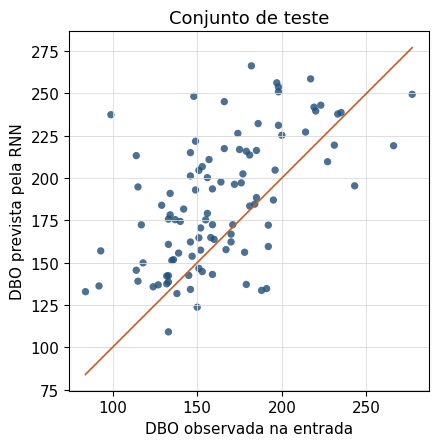

In [8]:
def salvar(fig, nome):
    fig.tight_layout()
    fig.savefig(FIGURAS / f"{nome}.pdf")
    fig.savefig(FIGURAS / f"{nome}.png", dpi=150)
    plt.show()


fig, ax = plt.subplots()
ax.scatter(y_teste, y_rnn, s=28, alpha=0.8, c=COR, edgecolors="none")
limites = [min(y_teste.min(), y_rnn.min()), max(y_teste.max(), y_rnn.max())]
ax.plot(limites, limites, color=COR_REF, linewidth=1.2)
ax.set_xlabel("DBO observada na entrada")
ax.set_ylabel("DBO prevista pela RNN")
ax.set_title("Conjunto de teste")
ax.set_aspect("equal", adjustable="box")
salvar(fig, "rnn_observado_previsto")


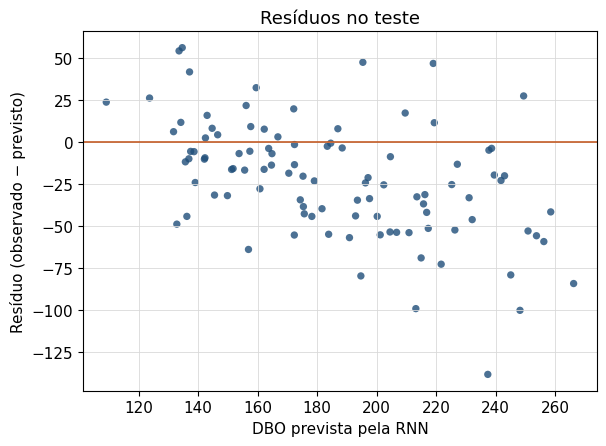

In [9]:
fig, ax = plt.subplots()
ax.scatter(y_rnn, residuo, s=28, alpha=0.8, c=COR, edgecolors="none")
ax.axhline(0, color=COR_REF, linewidth=1.2)
ax.set_xlabel("DBO prevista pela RNN")
ax.set_ylabel("Resíduo (observado − previsto)")
ax.set_title("Resíduos no teste")
salvar(fig, "rnn_residuos")


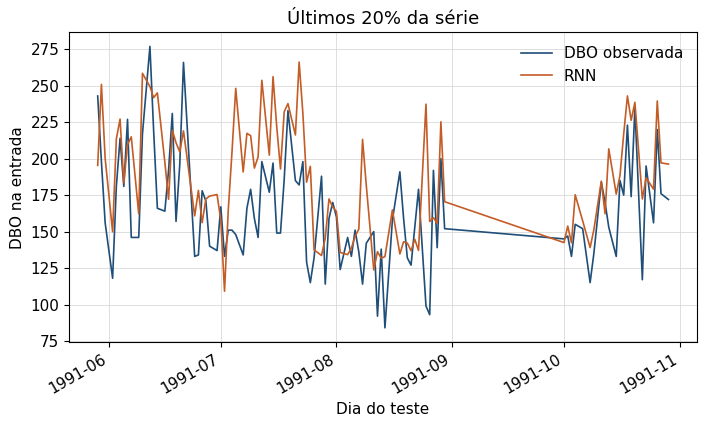

In [10]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.plot(data_teste, y_teste, color=COR, linewidth=1.2, label="DBO observada")
ax.plot(data_teste, y_rnn, color=COR_REF, linewidth=1.2, label="RNN")
ax.set_xlabel("Dia do teste")
ax.set_ylabel("DBO na entrada")
ax.set_title("Últimos 20% da série")
ax.legend(frameon=False)
fig.autofmt_xdate()
salvar(fig, "rnn_serie")


## Leitura

No teste cronológico, de 29 de maio a 29 de outubro de 1991, a RNN tem MAE 32,00, RMSE 40,68 e R² −0,23. A regressão linear da leitura mais recente tem MAE 33,13 e RMSE 40,75. A linear com as 10 leituras fica atrás, com MAE 34,08. A validação temporal escolheu estado de 8 unidades e taxa 0,01, com MAE 42,79 ± 3,94. Estados maiores não reduziram o erro.

A DBO média cai de 195 no treino para 164 no teste. A rede fica, em média, 22 unidades acima das observações finais. A DQO do dia estimado concentra o coeficiente da fila; as leituras anteriores não separam a RNN da reta de uma leitura.

A análise escrita está em docs/rnn_dbo_entrada.pdf.
